# Comparaison XGBoost / TabICL — prédiction conforme, Fitness Club

Ce notebook ne calcule rien : il lit `results_xgboost.csv` (écrit par `notebook_xgboost.ipynb`) et `results_tfm.csv` (écrit par `notebook_tfm.ipynb`). Si on modifie un des deux notebooks : le relancer (il réécrit son CSV), puis relancer celui-ci.

Les deux notebooks utilisent exactement les mêmes découpages (graine 90 + graines 0, 1, 2, 3) et les mêmes fonctions conformes ; seul le modèle change.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dossier = Path.cwd()
xgb = pd.read_csv(dossier / "results_xgboost.csv")
tfm = pd.read_csv(dossier / "results_tfm.csv")
res = pd.concat([xgb.assign(m="XGBoost"), tfm.assign(m="TabICL")], ignore_index=True)
print("Modèles :", xgb.modele.iloc[0], "|", tfm.modele.iloc[0])
ordre = {"Split": 0, "CV+": 1, "Jackknife+": 2}

Modèles : XGBoost | TabICL 2.2.0 (mps)


## 1. Graine 90 : ensembles conformes

Même découpage (graine 90) pour les deux modèles. Couverture visée = 1 − alpha.

In [2]:
p90 = res[res.source == "principal"]
t1 = p90.pivot_table(index=["methode", "alpha"], columns="m",
                     values=["coverage", "avg_set_size", "singleton_rate"])
t1 = t1.sort_index(key=lambda s: s.map(ordre) if s.name == "methode" else s)
display(t1.round(3))

avg_set_size         coverage         singleton_rate        
m                      TabICL XGBoost   TabICL XGBoost         TabICL XGBoost
methode    alpha                                                             
Split      0.05         1.536   1.571    0.965   0.949          0.464   0.429
           0.10         1.381   1.384    0.931   0.904          0.619   0.616
           0.20         1.091   1.115    0.835   0.805          0.909   0.885
CV+        0.05         1.507   1.595    0.960   0.971          0.493   0.405
           0.10         1.355   1.408    0.920   0.925          0.645   0.592
           0.20         1.056   1.099    0.824   0.813          0.944   0.901
Jackknife+ 0.05         1.507   1.587    0.960   0.960          0.493   0.413
           0.10         1.363   1.397    0.925   0.907          0.637   0.603
           0.20         1.059   1.077    0.824   0.795          0.941   0.923

## 2. Graine 90 : qualité du modèle et temps

Prédiction ponctuelle : Split = modèle entraîné sur la partie entraînement ; CV+ / Jackknife+ = moyenne des probas des modèles leave-out. Les temps n'ont de sens que si les deux notebooks ont tourné sur la même machine.

In [3]:
t2 = (p90[p90.alpha == p90.alpha.min()]
      .pivot_table(index="methode", columns="m", values=["accuracy", "precision_macro", "recall_macro", "f1_macro", "temps_s"]))
t2 = t2.sort_index(key=lambda s: s.map(ordre))
display(t2.round(3))
print("Classe majoritaire (toujours « No ») : accuracy 0.696")

accuracy         f1_macro         precision_macro          \
m            TabICL XGBoost   TabICL XGBoost          TabICL XGBoost   
methode                                                                
Split         0.797   0.763    0.738   0.698           0.774   0.721   
CV+           0.797   0.765    0.741   0.704           0.770   0.724   
Jackknife+    0.797   0.771    0.741   0.710           0.770   0.731   

           recall_macro           temps_s          
m                TabICL XGBoost    TabICL XGBoost  
methode                                            
Split             0.721   0.686     3.742   0.011  
CV+               0.726   0.693    23.558   0.119  
Jackknife+        0.726   0.699  1937.818  13.220

Classe majoritaire (toujours « No ») : accuracy 0.696


## 3. Sur 5 graines (0, 1, 2, 3, 90) : moyenne ± écart-type

Split et CV+ : moyenne ± écart-type sur les 5 graines. Jackknife+ n'est calculé que sur la graine 90 (trop long pour TabICL sur 5 graines) : on affiche sa valeur sur cette graine, sans écart-type, pour pouvoir quand même le comparer.

In [4]:
mg = res[res.source == "multi_graines"]
cols = ["coverage", "avg_set_size", "singleton_rate", "accuracy", "f1_macro"]
agg = mg.groupby(["methode", "alpha", "m"])[cols].agg(["mean", "std"])
fmt = pd.DataFrame({col: agg[(col, "mean")].map("{:.3f}".format) + " ± " + agg[(col, "std")].map("{:.3f}".format)
                    for col in cols})

# Jackknife+ : graine 90 seulement, sans écart-type
jk = p90[p90.methode == "Jackknife+"].set_index(["methode", "alpha", "m"])
fmt_jk = pd.DataFrame({col: jk[col].map("{:.3f}".format) + " (graine 90)" for col in cols})

fmt = pd.concat([fmt, fmt_jk]).unstack("m")
fmt = fmt.sort_index(key=lambda s: s.map(ordre) if s.name == "methode" else s)
display(fmt)

coverage                          avg_set_size  \
m                            TabICL            XGBoost             TabICL   
methode    alpha                                                            
Split      0.05       0.956 ± 0.020      0.951 ± 0.008      1.499 ± 0.083   
           0.10       0.913 ± 0.029      0.901 ± 0.020      1.325 ± 0.084   
           0.20       0.818 ± 0.023      0.801 ± 0.033      1.061 ± 0.035   
CV+        0.05       0.959 ± 0.004      0.964 ± 0.009      1.489 ± 0.037   
           0.10       0.912 ± 0.020      0.921 ± 0.012      1.323 ± 0.052   
           0.20       0.809 ± 0.024      0.821 ± 0.033      1.041 ± 0.019   
Jackknife+ 0.05   0.960 (graine 90)  0.960 (graine 90)  1.507 (graine 90)   
           0.10   0.925 (graine 90)  0.907 (graine 90)  1.363 (graine 90)   
           0.20   0.824 (graine 90)  0.795 (graine 90)  1.059 (graine 90)   

                                        singleton_rate                     \
m                           XGBoost             TabICL            XGBoost   
methode    alpha                                                            
Split      0.05       1.549 ± 0.043      0.501 ± 0.083      0.451 ± 0.043   
           0.10       1.375 ± 0.056      0.675 ± 0.084      0.625 ± 0.056   
           0.20       1.105 ± 0.061      0.939 ± 0.035      0.895 ± 0.061   
CV+        0.05       1.588 ± 0.023      0.511 ± 0.037      0.412 ± 0.023   
           0.10       1.398 ± 0.037      0.677 ± 0.052      0.602 ± 0.037   
           0.20       1.119 ± 0.042      0.959 ± 0.019      0.881 ± 0.042   
Jackknife+ 0.05   1.587 (graine 90)  0.493 (graine 90)  0.413 (graine 90)   
           0.10   1.397 (graine 90)  0.637 (graine 90)  0.603 (graine 90)   
           0.20   1.077 (graine 90)  0.941 (graine 90)  0.923 (graine 90)   

                           accuracy                              f1_macro  \
m                            TabICL            XGBoost             TabICL   
methode    alpha                                                            
Split      0.05       0.789 ± 0.014      0.758 ± 0.017      0.726 ± 0.025   
           0.10       0.789 ± 0.014      0.758 ± 0.017      0.726 ± 0.025   
           0.20       0.789 ± 0.014      0.758 ± 0.017      0.726 ± 0.025   
CV+        0.05       0.787 ± 0.019      0.769 ± 0.024      0.725 ± 0.032   
           0.10       0.787 ± 0.019      0.769 ± 0.024      0.725 ± 0.032   
           0.20       0.787 ± 0.019      0.769 ± 0.024      0.725 ± 0.032   
Jackknife+ 0.05   0.797 (graine 90)  0.771 (graine 90)  0.741 (graine 90)   
           0.10   0.797 (graine 90)  0.771 (graine 90)  0.741 (graine 90)   
           0.20   0.797 (graine 90)  0.771 (graine 90)  0.741 (graine 90)   

                                     
m                           XGBoost  
methode    alpha                     
Split      0.05       0.698 ± 0.026  
           0.10       0.698 ± 0.026  
           0.20       0.698 ± 0.026  
CV+        0.05       0.708 ± 0.035  
           0.10       0.708 ± 0.035  
           0.20       0.708 ± 0.035  
Jackknife+ 0.05   0.710 (graine 90)  
           0.10   0.710 (graine 90)  
           0.20   0.710 (graine 90)

## 4. Différence appariée TabICL − XGBoost (même découpage)

Pour chaque graine $g$ (mêmes personnes en test pour les deux modèles) :

$$d\_coverage_g = \text{couverture}_{\text{TabICL}}(g) - \text{couverture}_{\text{XGBoost}}(g) \qquad d\_avg\_set\_size_g = \text{taille}_{\text{TabICL}}(g) - \text{taille}_{\text{XGBoost}}(g)$$

puis `mean` / `std` sur les 5 graines.

- `d_coverage` ≈ 0 : les deux modèles couvrent autant (> 0 : TabICL couvre plus).
- `d_avg_set_size` < 0 : TabICL donne des ensembles plus petits, donc plus de réponses sûres (ex. −0.075 ≈ 7.5 % de personnes en moins avec {No, Yes}).
- `TabICL_plus_petit` : nombre de graines où la taille TabICL est plus petite.
- Jackknife+ : graine 90 seulement, une seule différence, pas d'écart-type.

In [5]:
w = mg.pivot_table(index=["methode", "alpha", "graine"], columns="m", values=["coverage", "avg_set_size"])
diff = pd.DataFrame({
    "d_coverage": w[("coverage", "TabICL")] - w[("coverage", "XGBoost")],
    "d_avg_set_size": w[("avg_set_size", "TabICL")] - w[("avg_set_size", "XGBoost")],
})
resume = diff.groupby(["methode", "alpha"]).agg(["mean", "std"]).round(3)
n_graines = diff.groupby(["methode", "alpha"]).size()
resume[("d_avg_set_size", "TabICL_plus_petit")] = (
    (diff.d_avg_set_size < 0).groupby(["methode", "alpha"]).sum().astype(str) + " / " + n_graines.astype(str))

# Jackknife+ (graine 90) : une seule différence, pas d'écart-type
w90 = p90[p90.methode == "Jackknife+"].pivot_table(index=["methode", "alpha"], columns="m", values=["coverage", "avg_set_size"])
jk = pd.DataFrame(index=w90.index, columns=resume.columns)
jk[("d_coverage", "mean")] = (w90[("coverage", "TabICL")] - w90[("coverage", "XGBoost")]).round(3)
jk[("d_avg_set_size", "mean")] = (w90[("avg_set_size", "TabICL")] - w90[("avg_set_size", "XGBoost")]).round(3)
jk[("d_avg_set_size", "TabICL_plus_petit")] = (w90[("avg_set_size", "TabICL")] < w90[("avg_set_size", "XGBoost")]).astype(int).astype(str) + " / 1"

resume = pd.concat([resume, jk]).sort_index(key=lambda s: s.map(ordre) if s.name == "methode" else s)
display(resume.fillna("—"))

d_coverage        d_avg_set_size                         
                       mean    std           mean    std TabICL_plus_petit
methode    alpha                                                          
Split      0.05       0.005  0.014         -0.050  0.044             5 / 5
           0.10       0.012  0.022         -0.050  0.073             4 / 5
           0.20       0.017  0.021         -0.044  0.057             4 / 5
CV+        0.05      -0.005  0.006         -0.099  0.014             5 / 5
           0.10      -0.009  0.011         -0.075  0.026             5 / 5
           0.20      -0.013  0.025         -0.078  0.038             5 / 5
Jackknife+ 0.05       0.000      —         -0.080      —             1 / 1
           0.10       0.019      —         -0.035      —             1 / 1
           0.20       0.029      —         -0.019      —             1 / 1

## 5. Graphes

**Figure 1** : un panneau par méthode, XGBoost et TabICL côte à côte pour chaque alpha.
- En haut : couverture obtenue − couverture visée (1 − alpha), en points. Au-dessus de 0 = garantie respectée. Valeur écrite : écart en points, et entre parenthèses la couverture obtenue (ex. +1.4 à α = 0.10 → 91.4 %).
- En bas : % de personnes avec l'ensemble {No, Yes} (« je ne sais pas ») = taille moyenne − 1. Plus bas = mieux.
- Barres = moyenne sur 5 graines, traits = écart-type. Jackknife+ : graine 90 seulement, sans écart-type.

**Figure 2** : différence TabICL − XGBoost du % de « je ne sais pas », graine par graine (points) et en moyenne (trait). Sous 0 = TabICL plus décidé.

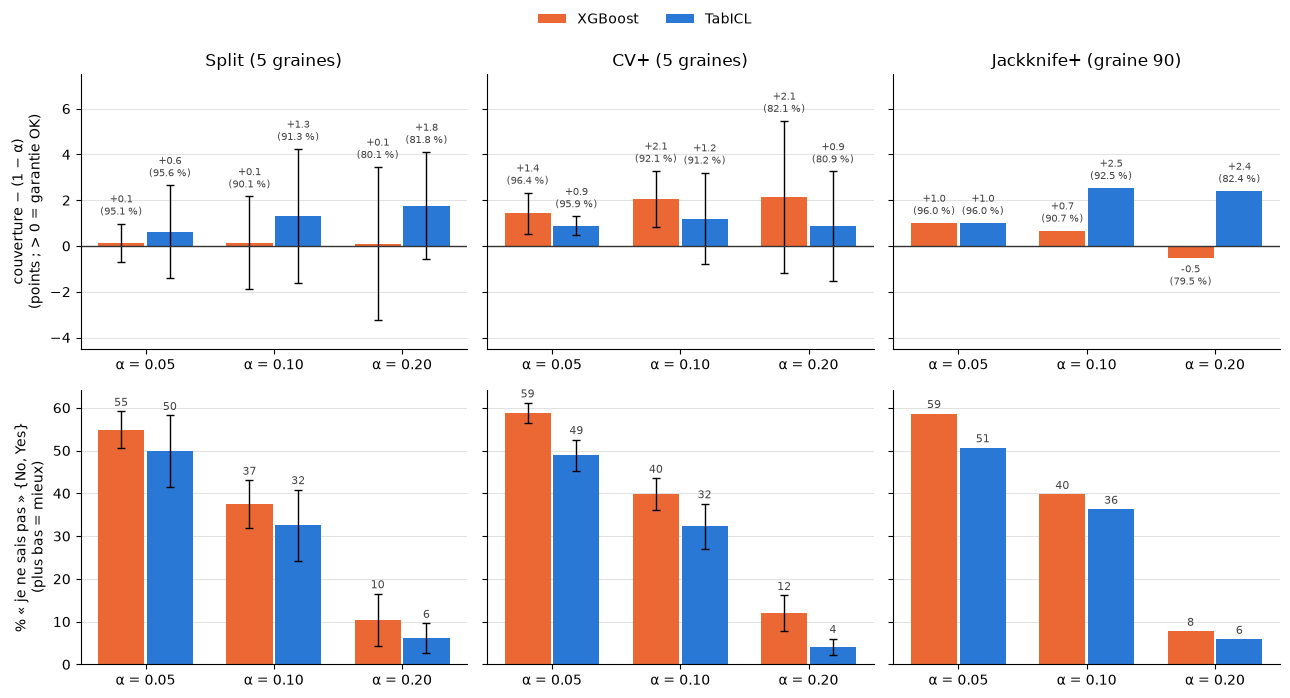

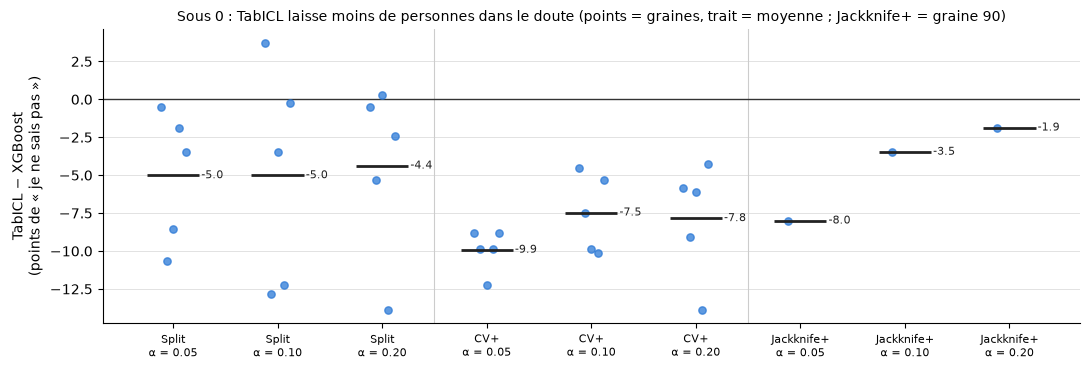

In [6]:
COUL = {"XGBoost": "#eb6834", "TabICL": "#2a78d6"}
MODELES = ["XGBoost", "TabICL"]
METHODES = ["Split", "CV+", "Jackknife+"]
alphas = sorted(res.alpha.unique())

def valeurs(meth, mod, col, echelle=100, decal=0):
    """Moyenne et écart-type (5 graines) ; Jackknife+ : graine 90, sans écart-type."""
    if meth == "Jackknife+":
        d = p90[(p90.methode == meth) & (p90.m == mod)].set_index("alpha").loc[alphas]
        return (d[col] - decal) * echelle, None
    d = mg[(mg.methode == meth) & (mg.m == mod)].groupby("alpha")[col]
    return (d.mean().loc[alphas] - decal) * echelle, d.std().loc[alphas] * echelle

# ---------- Figure 1 ----------
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey="row")
x = np.arange(len(alphas)); larg = 0.36
for j, meth in enumerate(METHODES):
    for k, mod in enumerate(MODELES):
        pos = x + (k - 0.5) * (larg + 0.02)
        # haut : écart à la couverture visée
        m, s = valeurs(meth, mod, "coverage", decal=0)
        m = m - (1 - np.array(alphas)) * 100
        axes[0, j].bar(pos, m, larg, yerr=s, capsize=3, color=COUL[mod], label=mod, error_kw={"lw": 1})
        # valeur : écart en points + couverture obtenue, écrite au-dessus (ou en dessous) du trait d'erreur
        haut = np.abs(m.values) + (0 if s is None else s.values) + 0.25
        for p_, v, h, a in zip(pos, m.values, haut, alphas):
            axes[0, j].annotate(f"{v:+.1f}\n({(1 - a) * 100 + v:.1f} %)", (p_, h if v >= 0 else -h),
                                ha="center", va="bottom" if v >= 0 else "top", fontsize=7, color="#444")
        # bas : % de « je ne sais pas »
        m2, s2 = valeurs(meth, mod, "avg_set_size", decal=1)
        b = axes[1, j].bar(pos, m2, larg, yerr=s2, capsize=3, color=COUL[mod], error_kw={"lw": 1})
        axes[1, j].bar_label(b, fmt="%.0f", padding=2, fontsize=8, color="#444")
    titre = meth + (" (graine 90)" if meth == "Jackknife+" else " (5 graines)")
    axes[0, j].set_title(titre)
    for i in range(2):
        axes[i, j].set_xticks(x, [f"α = {a:.2f}" for a in alphas])
        axes[i, j].spines[["top", "right"]].set_visible(False)
        axes[i, j].grid(axis="y", color="#ddd", lw=0.6); axes[i, j].set_axisbelow(True)
    axes[0, j].axhline(0, color="#333", lw=1)
    axes[0, j].set_ylim(-4.5, 7.5)
axes[0, 0].set_ylabel("couverture − (1 − α)\n(points ; > 0 = garantie OK)")
axes[1, 0].set_ylabel("% « je ne sais pas » {No, Yes}\n(plus bas = mieux)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

# ---------- Figure 2 ----------
fig, ax = plt.subplots(figsize=(11, 3.8))
etiquettes, i = [], 0
for meth in METHODES:
    for a in alphas:
        if meth == "Jackknife+":
            d = p90[(p90.methode == meth) & (p90.alpha == a)].set_index("m").avg_set_size
            pts = np.array([(d["TabICL"] - d["XGBoost"]) * 100])
        else:
            d = mg[(mg.methode == meth) & (mg.alpha == a)].pivot(index="graine", columns="m", values="avg_set_size")
            pts = ((d["TabICL"] - d["XGBoost"]) * 100).values
        ax.scatter(np.full(len(pts), i) + np.linspace(-0.12, 0.12, len(pts)), pts, s=28, color=COUL["TabICL"], alpha=0.75, zorder=3)
        ax.hlines(pts.mean(), i - 0.25, i + 0.25, color="#222", lw=2, zorder=4)
        ax.annotate(f"{pts.mean():+.1f}", (i + 0.27, pts.mean()), va="center", fontsize=8, color="#222")
        etiquettes.append(f"{meth}\nα = {a:.2f}"); i += 1
    if meth != METHODES[-1]:
        ax.axvline(i - 0.5, color="#ccc", lw=0.8)
ax.axhline(0, color="#333", lw=1)
ax.set_xticks(range(len(etiquettes)), etiquettes, fontsize=8)
ax.set_ylabel("TabICL − XGBoost\n(points de « je ne sais pas »)")
ax.set_title("Sous 0 : TabICL laisse moins de personnes dans le doute (points = graines, trait = moyenne ; Jackknife+ = graine 90)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#ddd", lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()